# Laboratorio #4 - Minería de datos (ISW-911)
**Universidad Técnica Nacional**

**Integrantes:**
- John Araya
- Ryan Vega 
- Juanda Gómez
- Emily Zuñiga

**Dataset:** Estadísticas Policiales 2025 - OIJ (Portal de Datos Abiertos del Poder Judicial)

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Lectura del dataset desde el repositorio público de GitHub
url = "https://raw.githubusercontent.com/JohnArayaE/lab4-mineria-datos/main/data/estadisticas_policiales_2025.csv"

# El archivo no trae fila de encabezados (header=None) y viene en latin-1 (tiene Ñ y tildes).
# 4 filas de 39,388 traen un campo de más (coma dentro de un valor); se descartan con
# on_bad_lines="warn" porque representan menos del 0.01% de los datos.
df = pd.read_csv(url, header=None, encoding="latin-1", on_bad_lines="warn")

df.shape

C:\Users\emily\AppData\Local\Temp\ipykernel_19244\3758378533.py:12: ParserWarning: Skipping line 5186: expected 11 fields, saw 12
Skipping line 27800: expected 11 fields, saw 12
Skipping line 29674: expected 11 fields, saw 12
Skipping line 30702: expected 11 fields, saw 12

  df = pd.read_csv(url, header=None, encoding="latin-1", on_bad_lines="warn")


(39384, 11)

## Punto 4: Características principales del conjunto de datos

In [3]:
# Primeras filas del dataset
df.head()

,0,1,2,3,4,5,6,7,8,9,10
0,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Desconocido,NaN,Desconocido,SAN JOSE,SAN JOSE,HOSPITAL
1,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Mayor de edad ...,NaN,COSTA RICA,SAN JOSE,SAN JOSE,CATEDRAL
2,ASALTO,CANDADO CHINO,2025-01-01,PERSONA,PEATON [PERSONA],Mayor de edad ...,NaN,COSTA RICA,PUNTARENAS,PUNTARENAS,PUNTARENAS
3,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Mayor de edad ...,NaN,COSTA RICA,SAN JOSE,TIBAS,SAN JUAN
4,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Desconocido,NaN,COSTA RICA,SAN JOSE,SAN JOSE,CATEDRAL


In [4]:
# Tipos de datos y cantidad de valores no nulos por columna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 39384 entries, 0 to 39383
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       39384 non-null  str    
 1   1       39384 non-null  str    
 2   2       39384 non-null  str    
 3   3       39384 non-null  str    
 4   4       39384 non-null  str    
 5   5       39384 non-null  str    
 6   6       0 non-null      float64
 7   7       39384 non-null  str    
 8   8       39384 non-null  str    
 9   9       39384 non-null  str    
 10  10      39384 non-null  str    
dtypes: float64(1), str(10)
memory usage: 3.3 MB


In [5]:
# Resumen estadístico (al ser columnas categóricas muestra: count, unique, top, freq)
df.describe(include="all")

,0,1,2,3,4,5,6,7,8,9,10
count,39384,39384,39384,39384,39384,39384,0.0,39384,39384,39384,39384
unique,6,39,365,4,79,4,NaN,79,8,85,385
top,HURTO,POR DESCUIDO,2025-11-01,PERSONA,PEATON [PERSONA],Mayor de edad ...,NaN,COSTA RICA,SAN JOSE,SAN JOSE,CATEDRAL
freq,12589,6789,182,16717,10076,33034,NaN,30656,15514,8684,1399
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Cantidad de valores únicos por columna
df.nunique()

0       6
1      39
2     365
3       4
4      79
5       4
6       0
7      79
8       8
9      85
10    385
dtype: int64

**Observaciones:**
- El dataset tiene 39,384 registros y 11 columnas, sin fila de encabezados.
- 10 columnas son de tipo texto (object), incluida la fecha, y 1 es float64 porque viene completamente vacía.
- La columna 6 (género) no tiene ningún valor registrado.
- El delito más frecuente es HURTO (12,589 registros) y la provincia con más registros es SAN JOSE (15,514).
- No hay variables numéricas originales; todas son categóricas.

## Punto 5: Cambio de nombres de las columnas a español

In [7]:
# El archivo no trae encabezados, se asignan nombres en español según el contenido de cada columna
df.columns = [
    "delito",
    "subdelito",
    "fecha",
    "victima",
    "subvictima",
    "edad",
    "genero",
    "nacionalidad",
    "provincia",
    "canton",
    "distrito"
]

df.head()

,delito,subdelito,fecha,victima,subvictima,edad,genero,nacionalidad,provincia,canton,distrito
0,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Desconocido,NaN,Desconocido,SAN JOSE,SAN JOSE,HOSPITAL
1,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Mayor de edad ...,NaN,COSTA RICA,SAN JOSE,SAN JOSE,CATEDRAL
2,ASALTO,CANDADO CHINO,2025-01-01,PERSONA,PEATON [PERSONA],Mayor de edad ...,NaN,COSTA RICA,PUNTARENAS,PUNTARENAS,PUNTARENAS
3,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Mayor de edad ...,NaN,COSTA RICA,SAN JOSE,TIBAS,SAN JUAN
4,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Desconocido,NaN,COSTA RICA,SAN JOSE,SAN JOSE,CATEDRAL


## Punto 6: Valores nulos

En el dataset los valores faltantes no solo vienen vacíos (NaN): también se registran con el texto "Desconocido".
Antes de contar los nulos se eliminan los espacios sobrantes de los textos y se reemplaza "Desconocido" por NaN,
para que se contabilicen como valores faltantes.

In [8]:
# Columnas de texto
cols_texto = df.select_dtypes(include="object").columns

# Quitar espacios al inicio y al final de los textos
df[cols_texto] = df[cols_texto].apply(lambda col: col.str.strip())

# Reemplazar "Desconocido" (sin importar mayúsculas/minúsculas) por NaN
df[cols_texto] = df[cols_texto].replace(r"(?i)^desconocido$", np.nan, regex=True)

# Cantidad y porcentaje de nulos por columna
nulos = pd.DataFrame({
    "cantidad_nulos": df.isnull().sum(),
    "porcentaje_nulos": (df.isnull().mean() * 100).round(2)
})

nulos

C:\Users\emily\AppData\Local\Temp\ipykernel_19244\2360280649.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols_texto = df.select_dtypes(include="object").columns


,cantidad_nulos,porcentaje_nulos
delito,0,0.00
subdelito,26,0.07
fecha,0,0.00
victima,0,0.00
subvictima,0,0.00
edad,2443,6.20
genero,39384,100.00
nacionalidad,2286,5.80
provincia,2,0.01
canton,115,0.29


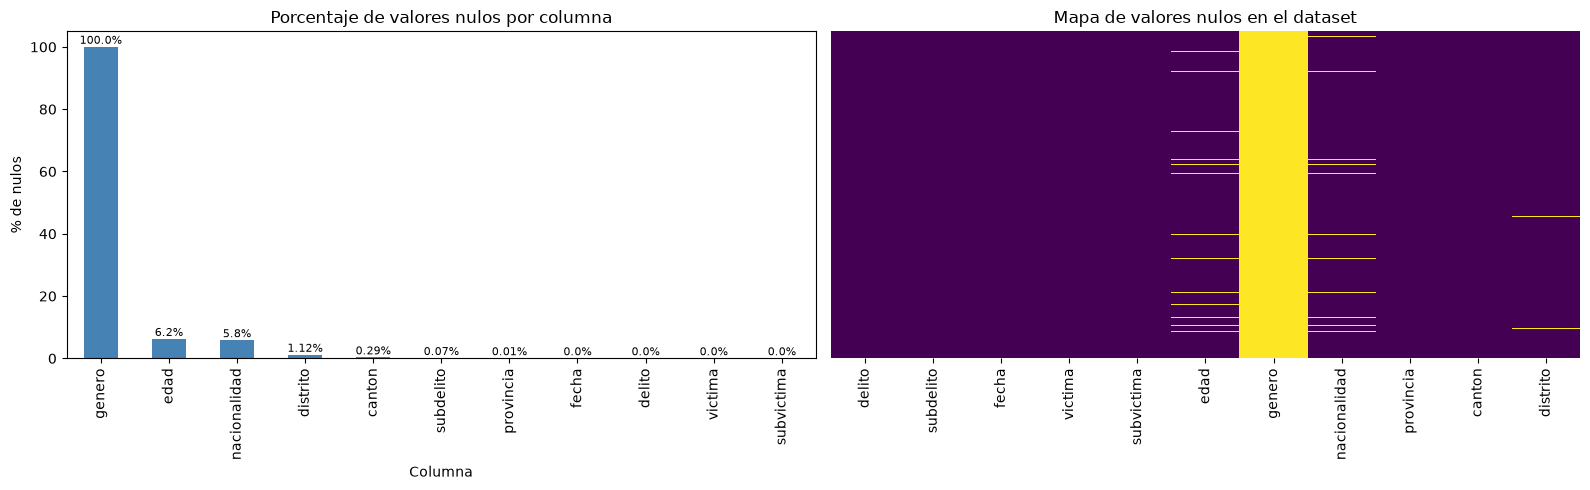

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico 1: porcentaje de nulos por columna
nulos["porcentaje_nulos"].sort_values(ascending=False).plot(
    kind="bar", ax=axes[0], color="steelblue"
)
axes[0].set_title("Porcentaje de valores nulos por columna")
axes[0].set_ylabel("% de nulos")
axes[0].set_xlabel("Columna")
for i, v in enumerate(nulos["porcentaje_nulos"].sort_values(ascending=False)):
    axes[0].text(i, v + 1, f"{v}%", ha="center", fontsize=8)

# Gráfico 2: mapa de calor de nulos (cada línea clara es un valor faltante)
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis", ax=axes[1])
axes[1].set_title("Mapa de valores nulos en el dataset")

plt.tight_layout()
plt.show()

**Hallazgos de valores nulos:**
- **genero**: 100% nulos. La columna no aporta información, por lo que se eliminará.
- **edad** (6.2%) y **nacionalidad** (5.8%): son los que más nulos tienen después de género. En 1,830 registros ambas faltan a la vez (se ve en el mapa de calor), lo que indica registros donde no se tomaron los datos de la víctima.
- **distrito** (1.12%), **canton** (0.29%), **subdelito** (0.07%) y **provincia** (0.01%): porcentaje muy bajo de nulos.
- **delito, fecha, victima y subvictima**: no tienen valores nulos.

---
## Punto 7: Valores atípicos

El dataset original no trae variables numéricas: todas son categóricas (delito, provincia, edad, etc.).
Los valores atípicos solo se pueden medir sobre variables numéricas, por eso se construyen dos
variables de **frecuencia** a partir de los datos:

- **delitos_por_dia**: cantidad de delitos registrados en cada fecha (365 días).
- **delitos_por_distrito**: cantidad de delitos registrados en cada distrito (provincia + cantón + distrito,
  porque hay distritos con el mismo nombre en cantones distintos, por ejemplo "SAN RAFAEL").

Para detectarlos se usa el **método del rango intercuartílico (IQR)**:
un valor es atípico si está por debajo de `Q1 - 1.5·IQR` o por encima de `Q3 + 1.5·IQR`.

In [10]:
def detectar_atipicos_iqr(serie, factor=1.5):
    """Devuelve los límites inferior/superior del IQR y una máscara con los valores atípicos."""
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - factor * iqr, q3 + factor * iqr
    mascara = (serie < lim_inf) | (serie > lim_sup)
    return lim_inf, lim_sup, mascara

# Variables numéricas de frecuencia
delitos_por_dia = df.groupby("fecha").size().rename("delitos_por_dia")
delitos_por_distrito = df.groupby(["provincia", "canton", "distrito"]).size().rename("delitos_por_distrito")

resumen_atipicos = []
for serie in [delitos_por_dia, delitos_por_distrito]:
    li, ls, m = detectar_atipicos_iqr(serie)
    resumen_atipicos.append({
        "variable": serie.name,
        "observaciones": len(serie),
        "Q1": serie.quantile(0.25), "Q3": serie.quantile(0.75),
        "limite_inferior": round(li, 2), "limite_superior": round(ls, 2),
        "cantidad_atipicos": int(m.sum()),
        "porcentaje_atipicos": round(m.mean() * 100, 2)
    })
pd.DataFrame(resumen_atipicos)

,variable,observaciones,Q1,Q3,limite_inferior,limite_superior,cantidad_atipicos,porcentaje_atipicos
0,delitos_por_dia,365,97.0,117.0,67.0,147.0,5,1.37
1,delitos_por_distrito,477,11.0,79.0,-91.0,181.0,47,9.85


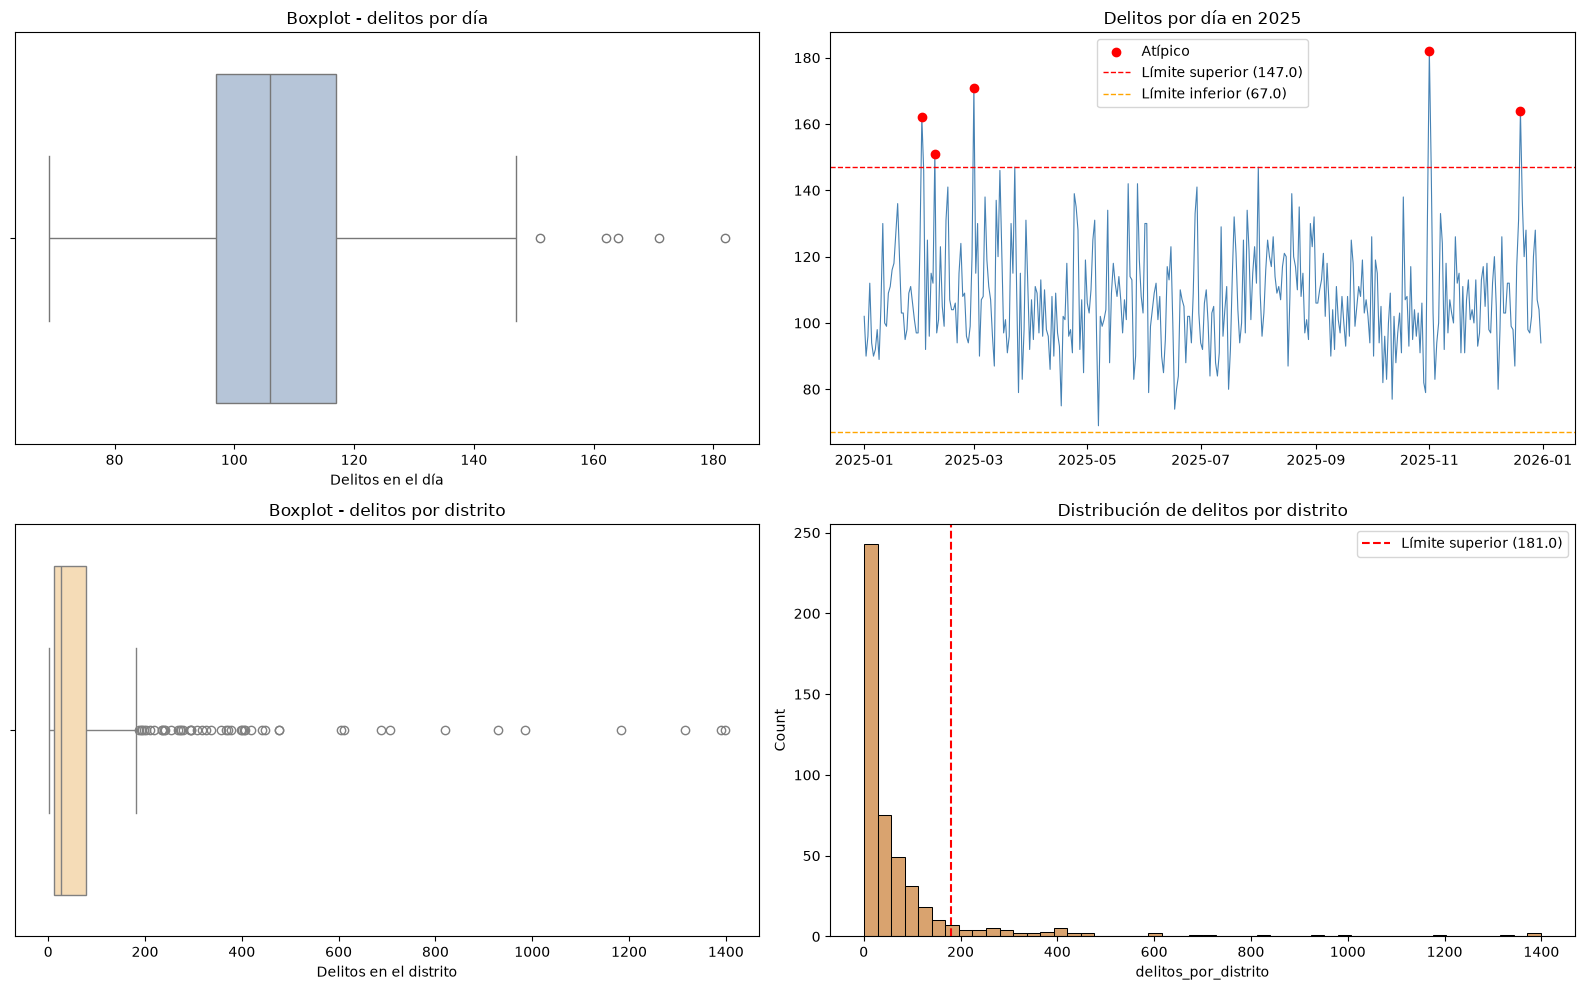

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Gráfico 1: boxplot de delitos por día
sns.boxplot(x=delitos_por_dia, ax=axes[0, 0], color="lightsteelblue")
axes[0, 0].set_title("Boxplot - delitos por día")
axes[0, 0].set_xlabel("Delitos en el día")

# Gráfico 2: delitos por día a lo largo del año, marcando los días atípicos
li, ls, m = detectar_atipicos_iqr(delitos_por_dia)
fechas = pd.to_datetime(delitos_por_dia.index)
axes[0, 1].plot(fechas, delitos_por_dia.values, color="steelblue", linewidth=0.8)
axes[0, 1].scatter(fechas[m.values], delitos_por_dia[m].values, color="red", zorder=3, label="Atípico")
axes[0, 1].axhline(ls, color="red", linestyle="--", linewidth=1, label=f"Límite superior ({ls:.1f})")
axes[0, 1].axhline(li, color="orange", linestyle="--", linewidth=1, label=f"Límite inferior ({li:.1f})")
axes[0, 1].set_title("Delitos por día en 2025")
axes[0, 1].legend()

# Gráfico 3: boxplot de delitos por distrito
sns.boxplot(x=delitos_por_distrito, ax=axes[1, 0], color="navajowhite")
axes[1, 0].set_title("Boxplot - delitos por distrito")
axes[1, 0].set_xlabel("Delitos en el distrito")

# Gráfico 4: histograma de delitos por distrito con el límite superior
li_d, ls_d, m_d = detectar_atipicos_iqr(delitos_por_distrito)
sns.histplot(delitos_por_distrito, bins=50, ax=axes[1, 1], color="peru")
axes[1, 1].axvline(ls_d, color="red", linestyle="--", label=f"Límite superior ({ls_d:.1f})")
axes[1, 1].set_title("Distribución de delitos por distrito")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

In [12]:
# Días atípicos (con el día de la semana para entender el contexto)
_, _, m = detectar_atipicos_iqr(delitos_por_dia)
dias_atipicos = delitos_por_dia[m].to_frame()
dias_atipicos["dia_semana"] = pd.to_datetime(dias_atipicos.index).day_name()
dias_atipicos.sort_values("delitos_por_dia", ascending=False)

,delitos_por_dia,dia_semana
fecha,,
2025-11-01,182,Saturday
2025-03-01,171,Saturday
2025-12-20,164,Saturday
2025-02-01,162,Saturday
2025-02-08,151,Saturday


In [13]:
# Distritos atípicos: los 15 con más delitos
_, _, m_d = detectar_atipicos_iqr(delitos_por_distrito)
delitos_por_distrito[m_d].sort_values(ascending=False).head(15).to_frame()

delitos_por_distrito
provincia  canton        distrito                           
SAN JOSE   SAN JOSE      CATEDRAL                       1399
                         HOSPITAL                       1391
                         MERCED                         1316
                         CARMEN                         1184
GUANACASTE LIBERIA       LIBERIA                         986
ALAJUELA   ALAJUELA      ALAJUELA                        929
SAN JOSE   SAN JOSE      PAVAS                           819
LIMON      LIMON         LIMON                           706
HEREDIA    HEREDIA       HEREDIA                         688
PUNTARENAS GARABITO      JACO                            611
SAN JOSE   MONTES DE OCA SAN PEDRO                       604
           SAN JOSE      HATILLO                         476
                         SAN SEBASTIAN                   476
                         MATA REDONDA                    447
                         URUCA                           442

**Hallazgos de valores atípicos:**
- **delitos_por_dia** (365 días): la mayoría de los días tiene entre 97 y 117 delitos (Q1–Q3). Hay **5 días atípicos**
  (1.37%) por encima del límite superior de 147: 2025-11-01 (182), 2025-03-01 (171), 2025-12-20 (164), 2025-02-01 (162)
  y 2025-02-08 (151). **Todos son sábados** y tres caen el día 1 del mes, lo que sugiere picos de fin de semana o
  registros acumulados en una misma fecha. No hay días atípicos por debajo del límite inferior (67).
- **delitos_por_distrito** (477 distritos): distribución muy asimétrica a la derecha. **47 distritos (9.85%)** superan el
  límite superior de 181 delitos. Los más extremos son los distritos centrales de San José (Catedral 1,399, Hospital 1,391,
  Merced 1,316, Carmen 1,184) y cabeceras como Liberia, Alajuela, Limón, Heredia y Jacó.
- En ambos casos los atípicos son **datos reales** (no errores de digitación): reflejan días con más actividad y la
  concentración de la delincuencia en zonas urbanas y turísticas. Por eso en el punto 8 no se eliminan filas,
  sino que se tratan con técnicas que reducen su efecto.

## Punto 8: Funciones de imputación

Se crean funciones para tratar lo encontrado en el punto 6 (valores nulos) y en el punto 7 (valores atípicos).
Cada función documenta la justificación de la acción aplicada.

| Hallazgo | Acción | Justificación |
|---|---|---|
| `genero` 100% nulo | Eliminar columna | No tiene ningún dato; imputarla sería inventar el 100% de los valores. |
| `provincia` nula (2 filas) | Eliminar filas | En esas filas faltan provincia, cantón y distrito a la vez; no hay de dónde deducir la ubicación y son el 0.005% del total. |
| `canton` nulo | Moda del cantón **dentro de su provincia** | El cantón depende de la provincia; usar la moda general pondría cantones de San José en otras provincias. |
| `distrito` nulo | Moda del distrito **dentro de su cantón** | Misma lógica jerárquica: el distrito tiene que pertenecer al cantón. |
| `subdelito` nulo | Moda del subdelito **dentro de su delito** | Cada subdelito pertenece a un delito; la moda general podría asignar un subdelito incompatible. |
| `edad` nula (6.2%) | Moda **dentro del tipo de víctima** | Variable categórica (no se puede usar media/mediana). Se agrupa por víctima porque el perfil cambia según si es persona, vivienda, vehículo, etc. |
| `nacionalidad` nula (5.8%) | Moda general | Variable categórica con una categoría muy dominante (Costa Rica, ~83%), la moda introduce poco sesgo. |
| Días atípicos (`delitos_por_dia`) | Acotar (winsorizar) a los límites del IQR del punto 7 | Son pocos días (5) y son registros **reales**, por eso no se eliminan filas; solo se limita el valor de la variable para que no distorsione la estandarización ni los modelos. |
| Distritos atípicos (`delitos_por_distrito`) | Transformación logarítmica `log(1 + x)` | Casi 10% de los distritos son atípicos porque la delincuencia se concentra en zonas urbanas: es una característica real, no un error. Acotar a 181 igualaría a Catedral (1,399) con un distrito de 181; el logaritmo conserva el orden y reduce la asimetría. |

In [14]:
def eliminar_columnas_vacias(data, umbral=0.9):
    """Elimina columnas con un porcentaje de nulos mayor al umbral (por defecto 90%).
    Justificación: una columna casi vacía no aporta información y no se puede imputar con fundamento."""
    porcentaje = data.isnull().mean()
    columnas = porcentaje[porcentaje > umbral].index.tolist()
    print(f"Columnas eliminadas por superar {umbral:.0%} de nulos: {columnas}")
    return data.drop(columns=columnas)


def eliminar_filas_nulas(data, columna):
    """Elimina las filas donde la columna indicada es nula.
    Justificación: se usa solo cuando el dato no se puede deducir de otras columnas y las filas son muy pocas."""
    antes = len(data)
    data = data.dropna(subset=[columna])
    print(f"Filas eliminadas por '{columna}' nula: {antes - len(data)}")
    return data


def imputar_moda(data, columna):
    """Rellena los nulos de una variable categórica con su valor más frecuente (moda).
    Justificación: en variables categóricas no existe media ni mediana; la moda es el valor más probable."""
    moda = data[columna].mode()[0]
    n = data[columna].isnull().sum()
    data[columna] = data[columna].fillna(moda)
    print(f"'{columna}': {n} nulos imputados con la moda '{moda}'")
    return data


def imputar_moda_por_grupo(data, columna, grupo):
    """Rellena los nulos con la moda de la columna dentro de cada grupo (ej. cantón dentro de provincia).
    Si un grupo no tiene ningún valor conocido, se usa la moda general como respaldo.
    Justificación: respeta la relación jerárquica entre variables y evita combinaciones imposibles."""
    n = data[columna].isnull().sum()
    moda_grupo = data.groupby(grupo)[columna].transform(
        lambda s: s.mode()[0] if not s.mode().empty else np.nan
    )
    data[columna] = data[columna].fillna(moda_grupo)
    data[columna] = data[columna].fillna(data[columna].mode()[0])
    print(f"'{columna}': {n} nulos imputados con la moda por grupo {grupo}")
    return data


def tratar_atipicos_iqr(data, columna, lim_inf, lim_sup):
    """Acota (winsoriza) los valores de una variable numérica a los límites del IQR calculados en el punto 7.
    Justificación: los días con muchos delitos son registros reales, por eso no se eliminan filas;
    solo se limita su magnitud para que no dominen la estandarización ni el modelo."""
    n = ((data[columna] < lim_inf) | (data[columna] > lim_sup)).sum()
    data[columna] = data[columna].clip(lower=lim_inf, upper=lim_sup)
    print(f"'{columna}': {n} registros acotados al rango [{lim_inf:.2f}, {lim_sup:.2f}]")
    return data


def transformar_log(data, columna):
    """Aplica log(1 + x) a una variable con asimetría fuerte a la derecha.
    Justificación: cuando los valores altos son parte de la estructura real de los datos (ej. los distritos
    centrales de San José concentran muchos más delitos), acotarlos borraría esa diferencia. El logaritmo
    conserva el orden entre distritos pero reduce la distancia de los extremos."""
    antes = data[columna].skew()
    data[columna] = np.log1p(data[columna])
    print(f"'{columna}': asimetría {antes:.2f} -> {data[columna].skew():.2f} tras aplicar log(1+x)")
    return data

In [15]:
# Respaldo del dataset antes de imputar (para comparar)
df_antes = df.copy()

# 1. Nulos (hallazgos del punto 6)
df = eliminar_columnas_vacias(df)
df = eliminar_filas_nulas(df, "provincia")
df = imputar_moda_por_grupo(df, "canton", ["provincia"])
df = imputar_moda_por_grupo(df, "distrito", ["provincia", "canton"])
df = imputar_moda_por_grupo(df, "subdelito", ["delito"])
df = imputar_moda_por_grupo(df, "edad", ["victima"])
df = imputar_moda(df, "nacionalidad")
df = df.reset_index(drop=True)

# 2. Atípicos (hallazgos del punto 7): se agregan las variables de frecuencia a cada registro
#    - delitos_por_dia: se acota a los límites IQR del punto 7
#    - delitos_por_distrito: se transforma con logaritmo (ver justificación en la función)
df["delitos_por_dia"] = df.groupby("fecha")["delito"].transform("size")
df["delitos_por_distrito"] = df.groupby(["provincia", "canton", "distrito"])["delito"].transform("size")
li_dia, ls_dia, _ = detectar_atipicos_iqr(delitos_por_dia)   # límites del punto 7
df = tratar_atipicos_iqr(df, "delitos_por_dia", li_dia, ls_dia)
df = transformar_log(df, "delitos_por_distrito")

print("\nNulos restantes:", int(df.isnull().sum().sum()))
print("Dimensiones:", df.shape)

Columnas eliminadas por superar 90% de nulos: ['genero']
Filas eliminadas por 'provincia' nula: 2
'canton': 113 nulos imputados con la moda por grupo ['provincia']
'distrito': 439 nulos imputados con la moda por grupo ['provincia', 'canton']
'subdelito': 26 nulos imputados con la moda por grupo ['delito']
'edad': 2442 nulos imputados con la moda por grupo ['victima']
'nacionalidad': 2285 nulos imputados con la moda 'COSTA RICA'
'delitos_por_dia': 830 registros acotados al rango [67.00, 147.00]
'delitos_por_distrito': asimetría 1.27 -> -0.39 tras aplicar log(1+x)

Nulos restantes: 0
Dimensiones: (39382, 12)


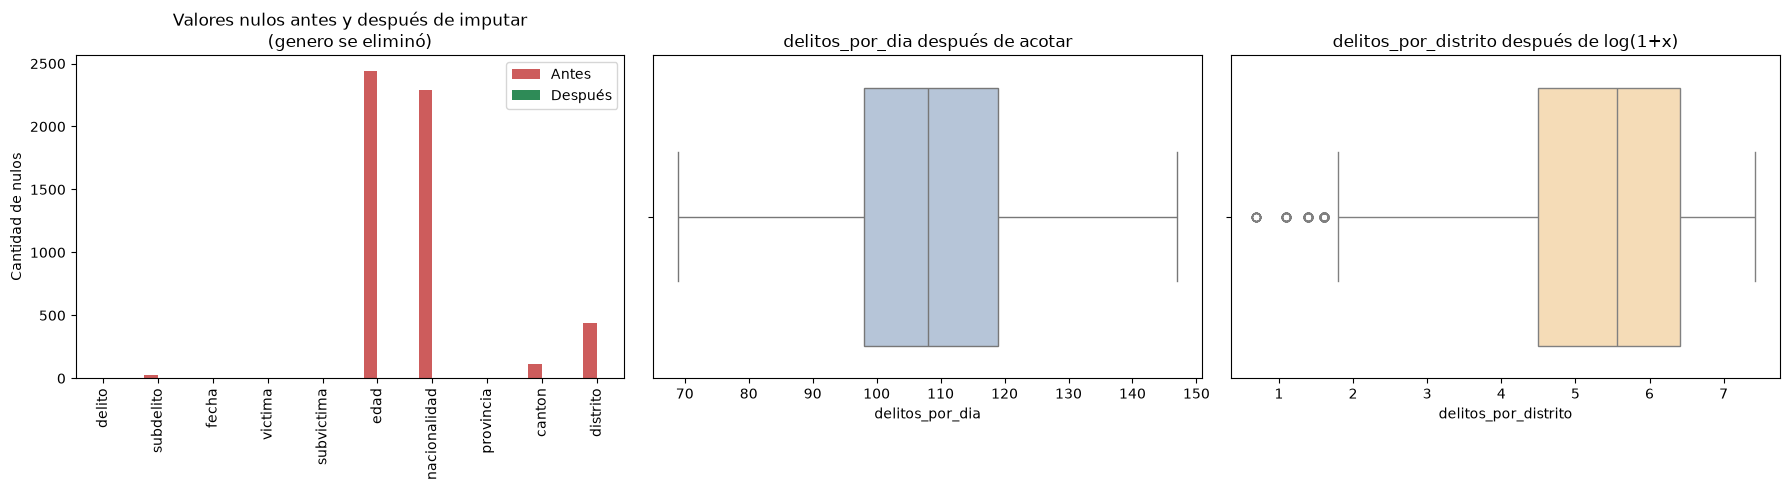

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: nulos antes vs después de la imputación
comparacion = pd.DataFrame({
    "Antes": df_antes.isnull().sum(),
    "Después": pd.Series({c: df[c].isnull().sum() if c in df.columns else 0 for c in df_antes.columns})
}).drop(index="genero")
comparacion.plot(kind="bar", ax=axes[0], color=["indianred", "seagreen"])
axes[0].set_title("Valores nulos antes y después de imputar\n(genero se eliminó)")
axes[0].set_ylabel("Cantidad de nulos")

# Gráfico 2 y 3: boxplots de las variables de frecuencia ya acotadas
sns.boxplot(x=df["delitos_por_dia"], ax=axes[1], color="lightsteelblue")
axes[1].set_title("delitos_por_dia después de acotar")
sns.boxplot(x=df["delitos_por_distrito"], ax=axes[2], color="navajowhite")
axes[2].set_title("delitos_por_distrito después de log(1+x)")

plt.tight_layout()
plt.show()

In [17]:
# Distribución de edad antes y después (verifica que la imputación no cambió la proporción de forma drástica)
pd.DataFrame({
    "antes_%": df_antes["edad"].value_counts(normalize=True).mul(100).round(2),
    "despues_%": df["edad"].value_counts(normalize=True).mul(100).round(2)
})

,antes_%,despues_%
edad,,
Mayor de edad,89.42,90.08
Adulto Mayor,8.11,7.61
Menor de edad,2.47,2.31


## Punto 9: Conversión de tipos de datos

- **fecha**: viene como texto (`object`), se convierte a `datetime64` y de ella se extraen variables numéricas
  útiles para el análisis: **mes**, **dia_mes**, **dia_semana** (0 = lunes ... 6 = domingo) y **fin_de_semana** (0/1).
- **Variables categóricas** (delito, subdelito, victima, subvictima, edad, nacionalidad, provincia, canton, distrito):
  se convierten de `object` a `category`, que es el tipo correcto para variables con un número limitado de valores
  y además reduce el uso de memoria.
- **delitos_por_dia**: después de acotar queda como `float`; se pasa a `int64` porque es un conteo.
- **delitos_por_distrito**: queda como `float64` porque, tras el logaritmo, ya no es un número entero.

In [18]:
memoria_antes = df.memory_usage(deep=True).sum() / 1024**2

# Fecha: texto -> datetime y variables derivadas
df["fecha"] = pd.to_datetime(df["fecha"], format="%Y-%m-%d")
df["mes"] = df["fecha"].dt.month.astype("int64")
df["dia_mes"] = df["fecha"].dt.day.astype("int64")
df["dia_semana"] = df["fecha"].dt.dayofweek.astype("int64")
df["fin_de_semana"] = (df["dia_semana"] >= 5).astype("int64")

# Categóricas: object -> category
cols_categoricas = ["delito", "subdelito", "victima", "subvictima", "edad",
                    "nacionalidad", "provincia", "canton", "distrito"]
df[cols_categoricas] = df[cols_categoricas].astype("category")

# Conteo: float -> int (delitos_por_distrito se mantiene float por la transformación logarítmica)
df["delitos_por_dia"] = df["delitos_por_dia"].round().astype("int64")
df["delitos_por_distrito"] = df["delitos_por_distrito"].astype("float64")

memoria_despues = df.memory_usage(deep=True).sum() / 1024**2
print(f"Memoria: {memoria_antes:.2f} MB -> {memoria_despues:.2f} MB")
df.info()

Memoria: 23.13 MB -> 2.52 MB
<class 'pandas.DataFrame'>
RangeIndex: 39382 entries, 0 to 39381
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   delito                39382 non-null  category      
 1   subdelito             39382 non-null  category      
 2   fecha                 39382 non-null  datetime64[us]
 3   victima               39382 non-null  category      
 4   subvictima            39382 non-null  category      
 5   edad                  39382 non-null  category      
 6   nacionalidad          39382 non-null  category      
 7   provincia             39382 non-null  category      
 8   canton                39382 non-null  category      
 9   distrito              39382 non-null  category      
 10  delitos_por_dia       39382 non-null  int64         
 11  delitos_por_distrito  39382 non-null  float64       
 12  mes                   39382 non-null  int64         
 13

C:\Users\emily\AppData\Local\Temp\ipykernel_19244\2767685367.py:7: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dia_semana"] = df["fecha"].dt.dayofweek.astype("int64")


In [19]:
df.head()

,delito,subdelito,fecha,victima,subvictima,edad,nacionalidad,provincia,canton,distrito,delitos_por_dia,delitos_por_distrito,mes,dia_mes,dia_semana,fin_de_semana
0,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Mayor de edad,COSTA RICA,SAN JOSE,SAN JOSE,HOSPITAL,102,7.238497,1,1,2,0
1,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Mayor de edad,COSTA RICA,SAN JOSE,SAN JOSE,CATEDRAL,102,7.424165,1,1,2,0
2,ASALTO,CANDADO CHINO,2025-01-01,PERSONA,PEATON [PERSONA],Mayor de edad,COSTA RICA,PUNTARENAS,PUNTARENAS,PUNTARENAS,102,5.267858,1,1,2,0
3,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Mayor de edad,COSTA RICA,SAN JOSE,TIBAS,SAN JUAN,102,5.620401,1,1,2,0
4,ASALTO,GOLPES,2025-01-01,PERSONA,PEATON [PERSONA],Mayor de edad,COSTA RICA,SAN JOSE,SAN JOSE,CATEDRAL,102,7.424165,1,1,2,0


## Punto 10: Conversión de variables categóricas a numéricas

Se usa una técnica distinta según el tipo de cada variable:

| Variable | Técnica | Justificación |
|---|---|---|
| `edad` | **Codificación ordinal** (Menor de edad = 0, Mayor de edad = 1, Adulto Mayor = 2) | Las categorías tienen un orden natural. |
| `victima` (4 valores), `provincia` (7 valores) | **One-Hot Encoding** | Son nominales (sin orden) y con pocas categorías, así que generan pocas columnas. |
| `subdelito`, `subvictima`, `nacionalidad`, `canton`, `distrito` | **Label Encoding** | Tienen muchas categorías (39 a ~470); One-Hot generaría cientos de columnas. Para `canton` y `distrito` se codifica la combinación con la provincia/cantón, porque hay nombres repetidos en distintos lugares. |
| `delito` | **Label Encoding** en una columna aparte (`delito_cod`) | Es la candidata a variable objetivo; se guarda la tabla de equivalencias para poder interpretar los resultados. |

In [20]:
from sklearn.preprocessing import LabelEncoder

df_num = df.copy()

# 1. Ordinal: edad
orden_edad = {"Menor de edad": 0, "Mayor de edad": 1, "Adulto Mayor": 2}
df_num["edad_cod"] = df_num["edad"].map(orden_edad).astype("int64")

# 2. Label Encoding: variables con muchas categorías
df_num["canton"] = df_num["provincia"].astype(str) + " | " + df_num["canton"].astype(str)
df_num["distrito"] = df_num["canton"] + " | " + df_num["distrito"].astype(str)

codificadores = {}
for col in ["delito", "subdelito", "subvictima", "nacionalidad", "canton", "distrito"]:
    le = LabelEncoder()
    df_num[f"{col}_cod"] = le.fit_transform(df_num[col].astype(str))
    codificadores[col] = le
    print(f"{col}: {len(le.classes_)} categorías")

# 3. One-Hot: victima y provincia
df_num = pd.get_dummies(df_num, columns=["victima", "provincia"], prefix=["victima", "prov"], dtype="int64")

# Tabla de equivalencias de la variable objetivo
pd.DataFrame({"delito": codificadores["delito"].classes_,
              "delito_cod": range(len(codificadores["delito"].classes_))})

delito: 6 categorías
subdelito: 38 categorías
subvictima: 79 categorías
nacionalidad: 78 categorías
canton: 84 categorías
distrito: 477 categorías


,delito,delito_cod
0,ASALTO,0
1,HOMICIDIO,1
2,HURTO,2
3,ROBO,3
4,ROBO DE VEHICULO,4
5,TACHA DE VEHICULO,5


In [21]:
# Dataset solo con variables numéricas (se quitan las columnas de texto originales y la fecha,
# cuya información ya quedó en mes, dia_mes, dia_semana y fin_de_semana)
cols_texto_originales = ["delito", "subdelito", "subvictima", "edad", "nacionalidad", "canton", "distrito", "fecha"]
df_num = df_num.drop(columns=cols_texto_originales)

print("Dimensiones:", df_num.shape)
print("Tipos:", df_num.dtypes.value_counts().to_dict())
df_num.head()

Dimensiones: (39382, 24)
Tipos: {dtype('int64'): 23, dtype('float64'): 1}


,delitos_por_dia,delitos_por_distrito,mes,dia_mes,dia_semana,fin_de_semana,edad_cod,delito_cod,subdelito_cod,subvictima_cod,...,victima_PERSONA,victima_VEHICULO,victima_VIVIENDA,prov_ALAJUELA,prov_CARTAGO,prov_GUANACASTE,prov_HEREDIA,prov_LIMON,prov_PUNTARENAS,prov_SAN JOSE
0,102,7.238497,1,1,2,0,1,0,20,55,...,1,0,0,0,0,0,0,0,0,1
1,102,7.424165,1,1,2,0,1,0,20,55,...,1,0,0,0,0,0,0,0,0,1
2,102,5.267858,1,1,2,0,1,0,9,55,...,1,0,0,0,0,0,0,0,1,0
3,102,5.620401,1,1,2,0,1,0,20,55,...,1,0,0,0,0,0,0,0,0,1
4,102,7.424165,1,1,2,0,1,0,20,55,...,1,0,0,0,0,0,0,0,0,1


## Punto 11: Estandarización

Se aplica **estandarización (Z-score)** con `StandardScaler`: cada variable queda con media 0 y desviación estándar 1
(`z = (x - media) / desviación`).

**¿Por qué estandarización y no normalización (Min-Max)?**
- Las variables tienen escalas muy distintas (ej. `delitos_por_distrito` llega a cientos y `dia_semana` va de 0 a 6);
  sin escalar, las de mayor magnitud dominarían modelos basados en distancias o en gradiente (KNN, regresión logística, SVM).
- Min-Max es muy sensible a los extremos; aunque los atípicos ya se acotaron en el punto 8, el Z-score es más estable.
- Los modelos candidatos no exigen que los datos estén en el rango [0, 1].

**Qué NO se escala:**
- `delito_cod`: es la variable objetivo, debe conservar sus clases (0 a 5).
- Columnas One-Hot (`victima_*`, `prov_*`) y `fin_de_semana`: ya son binarias 0/1; escalarlas les quita su interpretación.

In [22]:
from sklearn.preprocessing import StandardScaler

objetivo = "delito_cod"
cols_binarias = [c for c in df_num.columns if c.startswith(("victima_", "prov_"))] + ["fin_de_semana"]
cols_escalar = [c for c in df_num.columns if c not in cols_binarias + [objetivo]]
print("Columnas a estandarizar:", cols_escalar)

escalador = StandardScaler()
df_esc = df_num.copy()
df_esc[cols_escalar] = escalador.fit_transform(df_num[cols_escalar])

# Verificación: media ~ 0 y desviación ~ 1
df_esc[cols_escalar].describe().loc[["mean", "std", "min", "max"]].round(3)

Columnas a estandarizar: ['delitos_por_dia', 'delitos_por_distrito', 'mes', 'dia_mes', 'dia_semana', 'edad_cod', 'subdelito_cod', 'subvictima_cod', 'nacionalidad_cod', 'canton_cod', 'distrito_cod']


,delitos_por_dia,delitos_por_distrito,mes,dia_mes,dia_semana,edad_cod,subdelito_cod,subvictima_cod,nacionalidad_cod,canton_cod,distrito_cod
mean,-0.000,-0.000,0.000,-0.000,0.000,0.000,0.000,-0.000,0.000,-0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
min,-2.587,-3.617,-1.594,-1.659,-1.543,-3.391,-1.702,-2.049,-1.393,-1.836,-1.972
max,2.345,1.543,1.586,1.725,1.447,3.050,1.924,1.878,4.341,1.275,1.297


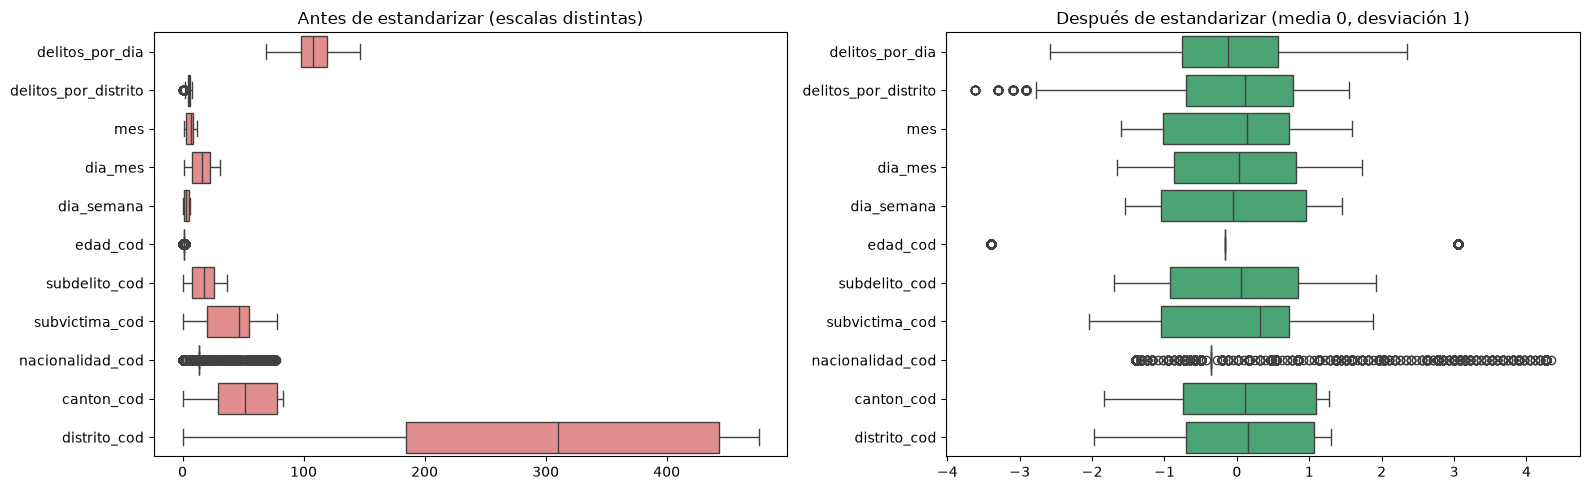

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Antes: cada variable en su propia escala
sns.boxplot(data=df_num[cols_escalar], ax=axes[0], orient="h", color="lightcoral")
axes[0].set_title("Antes de estandarizar (escalas distintas)")

# Después: todas centradas en 0 con la misma escala
sns.boxplot(data=df_esc[cols_escalar], ax=axes[1], orient="h", color="mediumseagreen")
axes[1].set_title("Después de estandarizar (media 0, desviación 1)")

plt.tight_layout()
plt.show()

## Punto 12: Correlación de las variables

Se usan dos medidas:
1. **Correlación de Pearson** sobre el dataset numérico estandarizado: mide relaciones lineales entre variables.
2. **V de Cramér** sobre las variables categóricas originales: Pearson no es adecuado para variables nominales
   codificadas con números (el número asignado a cada categoría es arbitrario), por eso se complementa con
   V de Cramér, que mide la asociación entre dos variables categóricas en una escala de 0 (ninguna) a 1 (total).

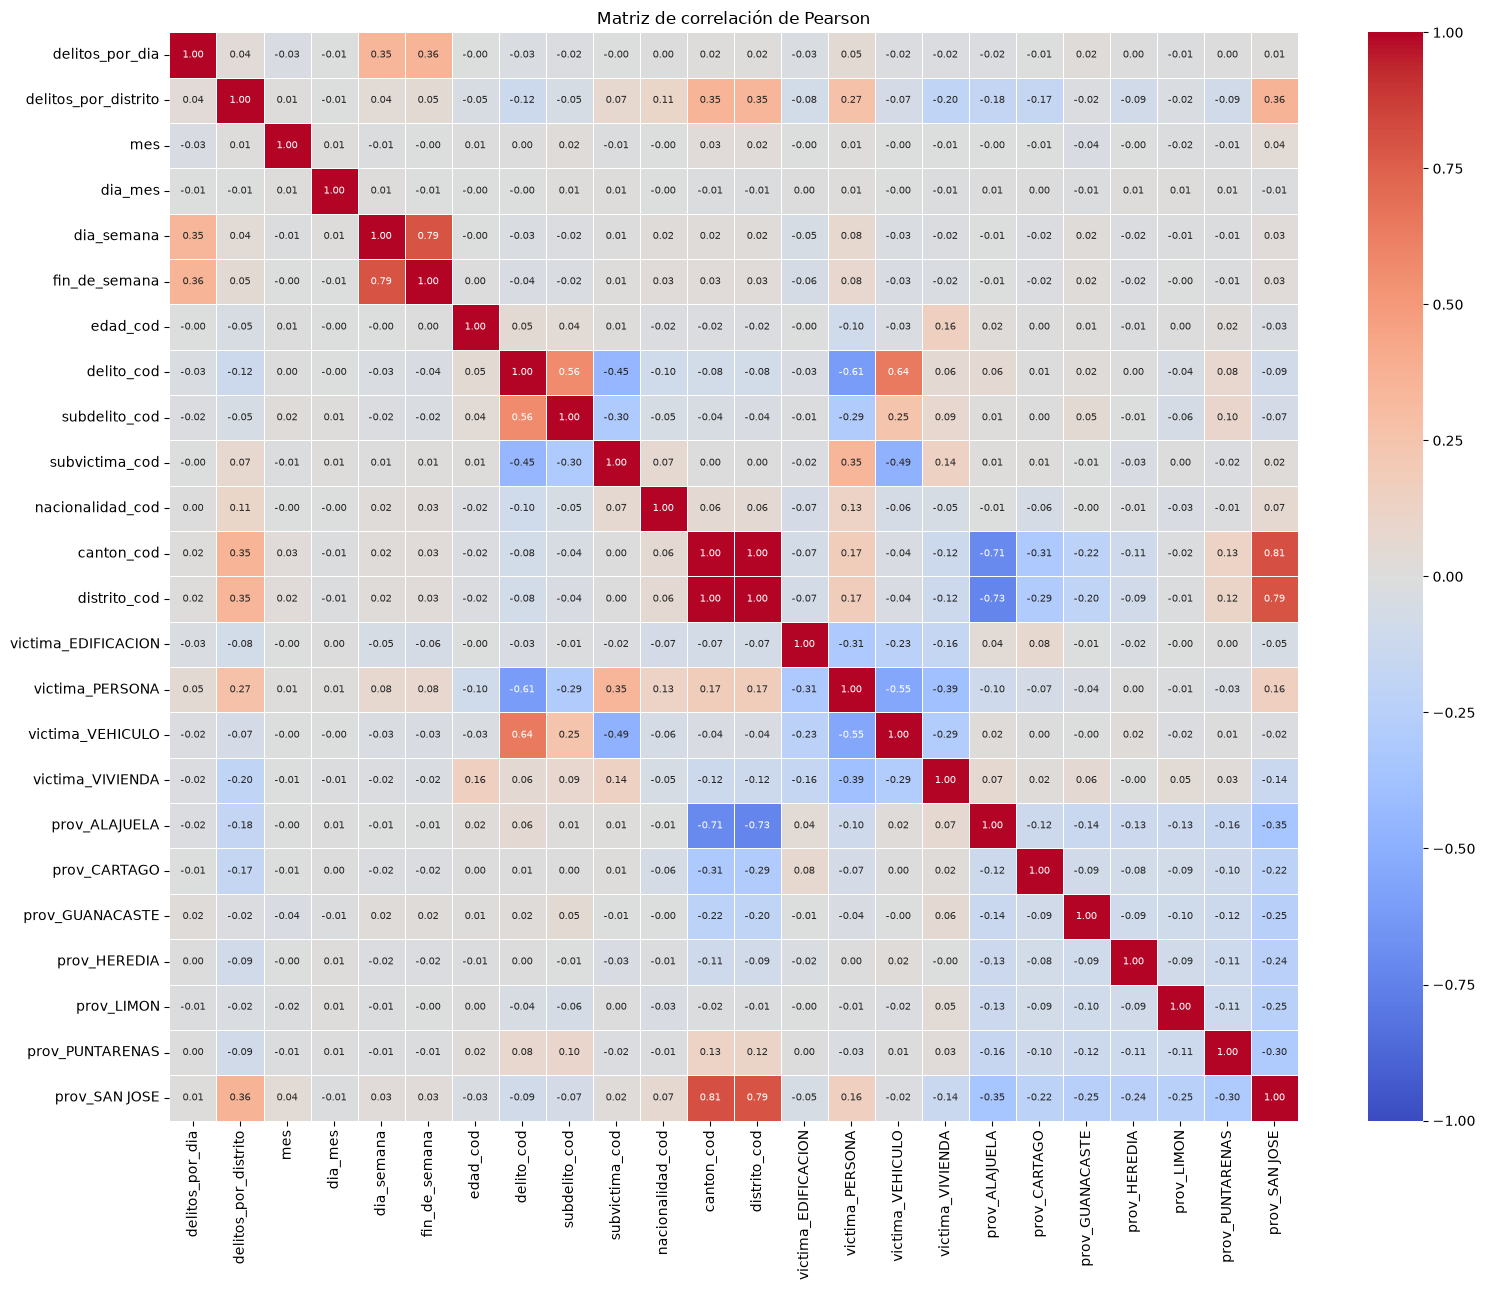

In [24]:
correlacion = df_esc.corr(method="pearson")

plt.figure(figsize=(16, 13))
sns.heatmap(correlacion, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.5, vmin=-1, vmax=1)
plt.title("Matriz de correlación de Pearson")
plt.tight_layout()
plt.show()

In [25]:
# Pares de variables con correlación fuerte (|r| >= 0.5), sin repetir pares
pares = (correlacion.where(np.triu(np.ones(correlacion.shape, dtype=bool), k=1))
         .stack().rename("r").reset_index())
pares["|r|"] = pares["r"].abs()
pares[pares["|r|"] >= 0.5].sort_values("|r|", ascending=False).round(3)

,level_0,level_1,r,|r|
276,canton_cod,distrito_cod,0.998,0.998
287,canton_cod,prov_SAN JOSE,0.806,0.806
311,distrito_cod,prov_SAN JOSE,0.795,0.795
101,dia_semana,fin_de_semana,0.793,0.793
305,distrito_cod,prov_ALAJUELA,-0.732,0.732
281,canton_cod,prov_ALAJUELA,-0.708,0.708
183,delito_cod,victima_VEHICULO,0.643,0.643
182,delito_cod,victima_PERSONA,-0.614,0.614
176,delito_cod,subdelito_cod,0.564,0.564
351,victima_PERSONA,victima_VEHICULO,-0.547,0.547


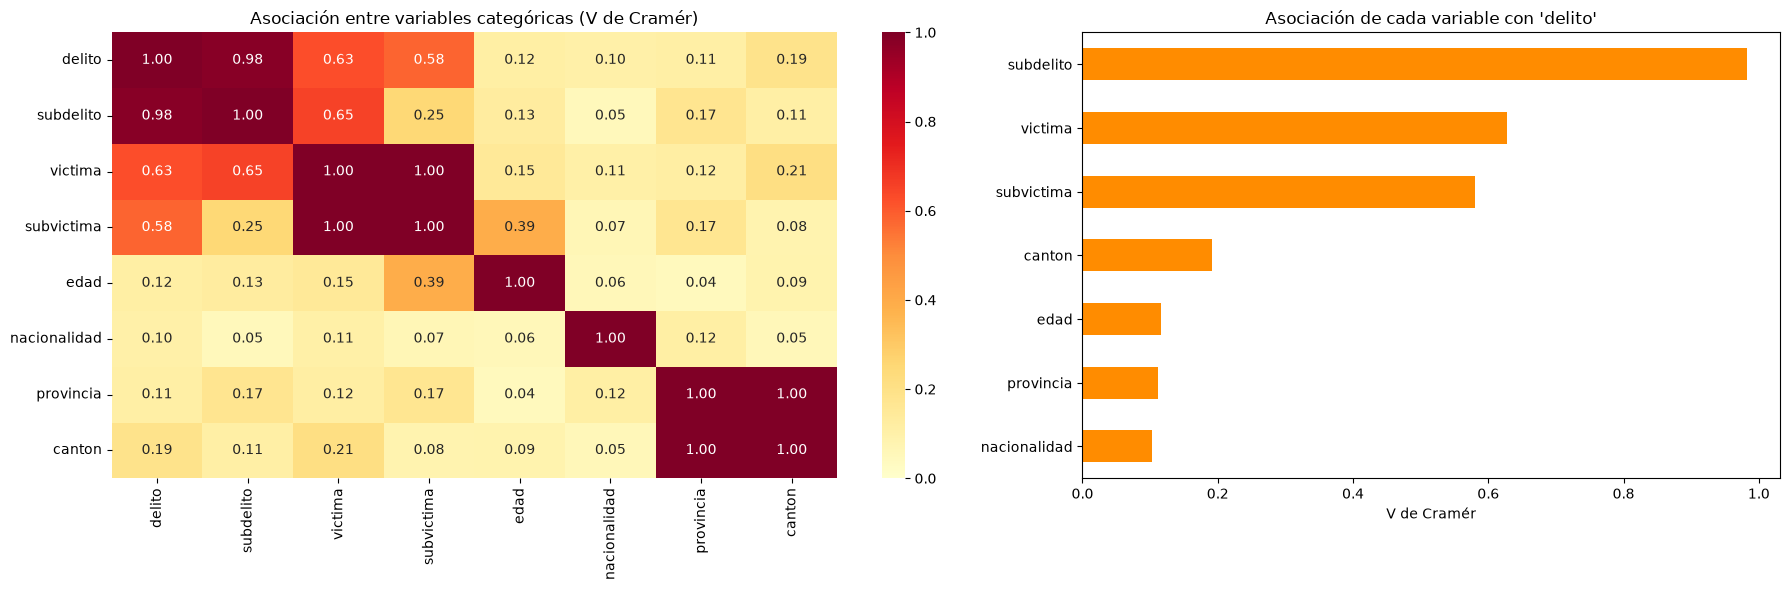

In [26]:
from scipy.stats import chi2_contingency

def v_cramer(x, y):
    """V de Cramér con corrección de sesgo (Bergsma, 2013)."""
    tabla = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabla, correction=False)[0]
    n = tabla.values.sum()
    phi2 = chi2 / n
    r, k = tabla.shape
    phi2_corr = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    r_corr = r - (r - 1) ** 2 / (n - 1)
    k_corr = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2_corr / max(1e-12, min(k_corr - 1, r_corr - 1)))

cols_cramer = ["delito", "subdelito", "victima", "subvictima", "edad", "nacionalidad", "provincia", "canton"]
matriz_cramer = pd.DataFrame(index=cols_cramer, columns=cols_cramer, dtype=float)
for a in cols_cramer:
    for b in cols_cramer:
        matriz_cramer.loc[a, b] = 1.0 if a == b else v_cramer(df[a], df[b])

fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1.3, 1]})

sns.heatmap(matriz_cramer, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1, ax=axes[0])
axes[0].set_title("Asociación entre variables categóricas (V de Cramér)")

matriz_cramer["delito"].drop("delito").sort_values().plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set_title("Asociación de cada variable con 'delito'")
axes[1].set_xlabel("V de Cramér")

plt.tight_layout()
plt.show()

**Hallazgos de correlación:**
- **Variable objetivo (`delito`)**: según V de Cramér, se asocia casi totalmente con **subdelito (0.98)**, y fuertemente
  con **victima (0.63)** y **subvictima (0.58)**. En Pearson se ve lo mismo: `delito_cod` con `victima_VEHICULO` (0.64),
  `victima_PERSONA` (-0.61) y `subdelito_cod` (0.56). Tiene sentido: robo/tacha de vehículo siempre recaen sobre un vehículo
  y el asalto sobre una persona.
- **Ojo con `subdelito`**: es una subcategoría del propio delito (ej. "POR DESCUIDO" solo aparece en HURTO), por lo que
  conocerlo prácticamente es conocer la respuesta. Si se usa en un modelo produciría **fuga de información (data leakage)**.
- **Variables redundantes entre sí**: `canton_cod` y `distrito_cod` (0.998), `provincia` y `canton` (V = 1.00),
  `victima` y `subvictima` (V = 1.00), y `dia_semana` con `fin_de_semana` (0.79). Cada par aporta casi la misma
  información (multicolinealidad), conviene quedarse con una de cada par en el modelo.
- `delitos_por_dia` se relaciona con `dia_semana`/`fin_de_semana` (~0.35): hay más delitos registrados los fines de semana,
  lo que concuerda con los días atípicos (todos sábados) del punto 7.
- **edad, nacionalidad, provincia, mes y dia_mes** tienen asociación muy baja con el tipo de delito (≤ 0.12): por sí solas
  aportan poco para predecirlo.

---
## Punto 13: Variable dependiente y modelo candidato

**Variable dependiente: `delito`** (codificada como `delito_cod`, 0 a 5).

Es la variable que el dataset describe: cada registro es un delito y el resto de columnas (víctima, edad, nacionalidad,
lugar y fecha) son las características del hecho. La pregunta natural del conjunto de datos es:
*dadas las circunstancias de un hecho, ¿qué tipo de delito es?*

**Tipo de problema: clasificación multiclase.** `delito` es categórica con 6 clases sin orden
(ASALTO, HOMICIDIO, HURTO, ROBO, ROBO DE VEHICULO, TACHA DE VEHICULO). No es un valor numérico continuo,
por lo que **no es un problema de regresión**.

**Variables que NO deben usarse como predictoras** (según los hallazgos del punto 12):
- `subdelito_cod`: es una subcategoría del propio delito (V de Cramér = 0.98). Usarla sería **fuga de información**:
  el modelo "vería la respuesta".
- `canton_cod` y `subvictima_cod`: son redundantes con `distrito_cod` (r = 0.998) y con `victima_*` (V = 1.00).
  Se deja una variable de cada par para evitar multicolinealidad.

                   cantidad  porcentaje
delito                                 
HURTO                 12587       31.96
ASALTO                 9424       23.93
ROBO                   6877       17.46
ROBO DE VEHICULO       5152       13.08
TACHA DE VEHICULO      4345       11.03
HOMICIDIO               997        2.53


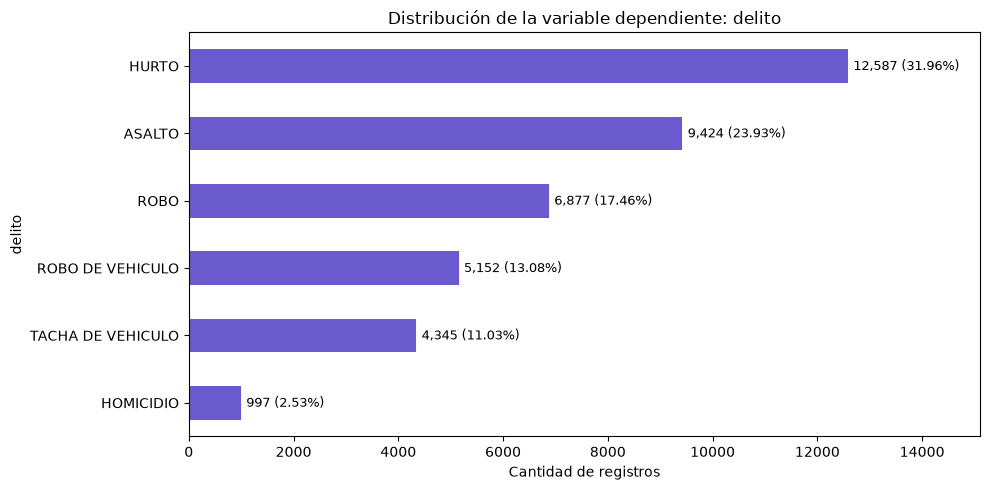

In [27]:
# Balance de clases de la variable objetivo
conteo = df["delito"].value_counts()
porcentaje = (conteo / conteo.sum() * 100).round(2)
print(pd.DataFrame({"cantidad": conteo, "porcentaje": porcentaje}))

plt.figure(figsize=(10, 5))
ax = conteo.sort_values().plot(kind="barh", color="slateblue")
for i, (v, p) in enumerate(zip(conteo.sort_values(), porcentaje.sort_values())):
    ax.text(v + 100, i, f"{v:,} ({p}%)", va="center", fontsize=9)
plt.title("Distribución de la variable dependiente: delito")
plt.xlabel("Cantidad de registros")
plt.xlim(0, conteo.max() * 1.2)
plt.tight_layout()
plt.show()

**Las clases están desbalanceadas:** HURTO representa el 32% de los registros y HOMICIDIO solo el 2.5%.
Un modelo que siempre responda "HURTO" acertaría el 32% de las veces sin aprender nada, por eso además de la
exactitud (*accuracy*) se debe revisar el **F1 macro**, que pesa igual a todas las clases.

Como verificación rápida (no es el modelo final, solo respalda la elección) se comparan los modelos de clasificación
estudiados sobre el dataset procesado, con 70% de entrenamiento y 30% de prueba, estratificado por clase.

Variables predictoras: 20
                            accuracy  f1_macro
modelo                                        
Línea base (siempre HURTO)     0.320     0.081
Regresión logística            0.443     0.424
KNN (k=15)                     0.513     0.447
Árbol de decisión              0.483     0.470
Random Forest                  0.546     0.524


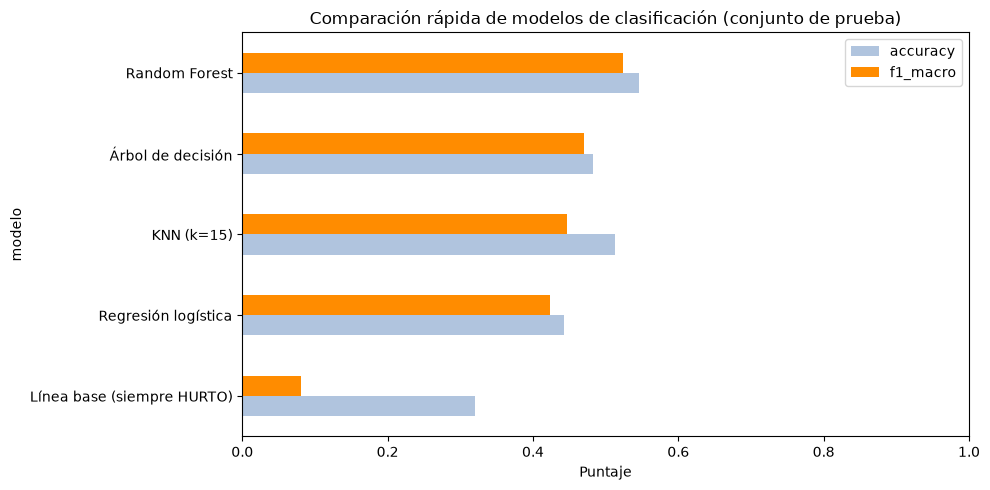

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# Predictoras: se excluyen la variable objetivo, subdelito (fuga de información) y las redundantes
excluir = [objetivo, "subdelito_cod", "canton_cod", "subvictima_cod"]
X = df_esc.drop(columns=excluir)
y = df_esc[objetivo]
print("Variables predictoras:", X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

modelos = {
    "Línea base (siempre HURTO)": DummyClassifier(strategy="most_frequent"),
    "Regresión logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "KNN (k=15)": KNeighborsClassifier(n_neighbors=15),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=10, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=15, class_weight="balanced",
                                            random_state=42, n_jobs=-1),
}

resultados = []
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    resultados.append({"modelo": nombre,
                       "accuracy": round(accuracy_score(y_test, pred), 3),
                       "f1_macro": round(f1_score(y_test, pred, average="macro"), 3)})
resultados = pd.DataFrame(resultados).set_index("modelo")
print(resultados)

resultados.plot(kind="barh", figsize=(10, 5), color=["lightsteelblue", "darkorange"])
plt.title("Comparación rápida de modelos de clasificación (conjunto de prueba)")
plt.xlabel("Puntaje")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

**Modelo candidato: Random Forest (bosque aleatorio) de clasificación.**

Justificación:
1. **Es un problema de clasificación multiclase** (6 tipos de delito) y Random Forest lo resuelve directamente,
   sin necesidad de adaptar el modelo.
2. **Obtuvo el mejor desempeño** en la comparación rápida, tanto en exactitud como en F1 macro, muy por encima de
   la línea base y de la regresión logística, KNN y el árbol de decisión individual.
3. **Maneja bien variables categóricas codificadas** con Label Encoding (`distrito_cod`, `nacionalidad_cod`):
   los árboles dividen por rangos y no asumen que la distancia entre códigos tenga significado, a diferencia de la
   regresión logística o KNN.
4. **Captura relaciones no lineales** entre variables (por ejemplo, el tipo de víctima combinado con la zona),
   que un modelo lineal no detecta.
5. **Es robusto a atípicos y a la multicolinealidad** que quedaron en los datos, porque combina muchos árboles
   entrenados sobre muestras distintas.
6. **Permite tratar el desbalance** con `class_weight="balanced"`, para que HOMICIDIO (2.5%) no quede ignorado.
7. Entrega la **importancia de cada variable**, lo que ayuda a explicar qué factores se asocian a cada tipo de delito.

Como alternativa más simple e interpretable se puede usar un **Árbol de decisión**: sus reglas se leen directamente
(por ejemplo, "si la víctima es un vehículo y ..."), aunque su desempeño es menor y tiende al sobreajuste.

**Limitación:** el desempeño de todos los modelos es moderado (~0.5), porque fuera de `victima` las variables
disponibles (fecha, edad, nacionalidad, lugar) tienen poca asociación con el tipo de delito (punto 12).
Para mejorarlo se podrían agregar variables como la hora del hecho, si el dataset la tuviera.

## Punto 14: Guardar el conjunto de datos resultante

Se guarda **`df_esc`**, que es el dataset con todas las actividades del EDA aplicadas:
- Columnas renombradas al español (punto 5).
- Nulos imputados y `genero` eliminada (puntos 6 y 8).
- Atípicos tratados: `delitos_por_dia` acotada y `delitos_por_distrito` con logaritmo (puntos 7 y 8).
- Tipos convertidos y variables de fecha derivadas (punto 9).
- Variables categóricas convertidas a numéricas (punto 10).
- Variables estandarizadas con Z-score (punto 11).

Se guarda con `index=False` para no agregar una columna extra con el índice. Después se vuelve a leer el archivo
para verificar que se guardó completo.

In [29]:
# Guardar el dataset procesado
df_esc.to_csv("data_process.csv", index=False, encoding="utf-8")

# Verificación: leer el archivo guardado y comparar con el DataFrame en memoria
df_verificacion = pd.read_csv("data_process.csv")
print("Archivo guardado: data_process.csv")
print("Dimensiones en memoria:", df_esc.shape)
print("Dimensiones del archivo:", df_verificacion.shape)
print("Nulos en el archivo:", int(df_verificacion.isnull().sum().sum()))
print("Columnas coinciden:", list(df_verificacion.columns) == list(df_esc.columns))
df_verificacion.head()

Archivo guardado: data_process.csv
Dimensiones en memoria: (39382, 24)
Dimensiones del archivo: (39382, 24)
Nulos en el archivo: 0
Columnas coinciden: True


,delitos_por_dia,delitos_por_distrito,mes,dia_mes,dia_semana,fin_de_semana,edad_cod,delito_cod,subdelito_cod,subvictima_cod,...,victima_PERSONA,victima_VEHICULO,victima_VIVIENDA,prov_ALAJUELA,prov_CARTAGO,prov_GUANACASTE,prov_HEREDIA,prov_LIMON,prov_PUNTARENAS,prov_SAN JOSE
0,-0.500283,1.400692,-1.594379,-1.659436,-0.546018,0,-0.170514,0,0.258320,0.720366,...,1,0,0,0,0,0,0,0,0,1
1,-0.500283,1.543027,-1.594379,-1.659436,-0.546018,0,-0.170514,0,0.258320,0.720366,...,1,0,0,0,0,0,0,0,0,1
2,-0.500283,-0.110020,-1.594379,-1.659436,-0.546018,0,-0.170514,0,-0.819729,0.720366,...,1,0,0,0,0,0,0,0,1,0
3,-0.500283,0.160243,-1.594379,-1.659436,-0.546018,0,-0.170514,0,0.258320,0.720366,...,1,0,0,0,0,0,0,0,0,1
4,-0.500283,1.543027,-1.594379,-1.659436,-0.546018,0,-0.170514,0,0.258320,0.720366,...,1,0,0,0,0,0,0,0,0,1
